# Analysis 1 — Treasury Market Conditions and Scenarios

## Setup — FRED observations

In [1]:
from pathlib import Path
from bondview.data.fred import FredDataManager
from bondview.presentation.widgets import DateRangePicker

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SNAPSHOT_DIR = PROJECT_ROOT / "data/fred"
fred = FredDataManager(SNAPSHOT_DIR, env_path=PROJECT_ROOT / ".env")

### Donwload

In [9]:
FRED_SERIES = (
    "DGS2", "DGS10", "DGS30",
    "THREEFY2", "THREEFYTP2", "THREEFY10", "THREEFYTP10",
)
start = None
end = None
downloaded = fred.download(series_ids=FRED_SERIES, start=start, end=end)

In [11]:
# Optional inspection; downloaded is also a DataFrame.
#fred.report(series_ids='DGS10')  
fred.report()

FRED observations (download)
Series ID             Nonmissing
DGS2                     12,597
DGS10                    16,189
DGS30                    12,419
THREEFY2                  9,189
THREEFYTP2                9,189
THREEFY10                 9,189
THREEFYTP10               9,189
Complete shared observations: 9,189


In [12]:
fred.save()

{'DGS2': PosixPath('/home/lbk/works/bondview-v3/data/fred/DGS2_20261028.csv'),
 'DGS10': PosixPath('/home/lbk/works/bondview-v3/data/fred/DGS10_20261028.csv'),
 'DGS30': PosixPath('/home/lbk/works/bondview-v3/data/fred/DGS30_20261028.csv'),
 'THREEFY2': PosixPath('/home/lbk/works/bondview-v3/data/fred/THREEFY2_20261028.csv'),
 'THREEFYTP2': PosixPath('/home/lbk/works/bondview-v3/data/fred/THREEFYTP2_20261028.csv'),
 'THREEFY10': PosixPath('/home/lbk/works/bondview-v3/data/fred/THREEFY10_20261028.csv'),
 'THREEFYTP10': PosixPath('/home/lbk/works/bondview-v3/data/fred/THREEFYTP10_20261028.csv')}

## A. Yield-curve conditions and movements

Examine 2Y, 10Y, and 30Y Treasury yields and compare available observations within the selected date range.

In [3]:
from bondview.analysis.treasury_curve import analyze_curve
from bondview.plotting.treasury_curve import show_yield_history
from bondview.presentation.treasury_curve import show_curve_results

*Load Treasury yield observations*

In [4]:
observations = fred.load(series_ids=["DGS2", "DGS10", "DGS30"])
fred.report()

FRED observations (file)
Series ID             Nonmissing
DGS2                     12,597
DGS10                    16,189
DGS30                    12,419
Complete shared observations: 12,419


### Treasury yield history

Plot historical 2Y, 10Y, and 30Y Treasury yields over the selected date range.

In [ ]:
date_range = DateRangePicker(observations)

In [5]:
date_range

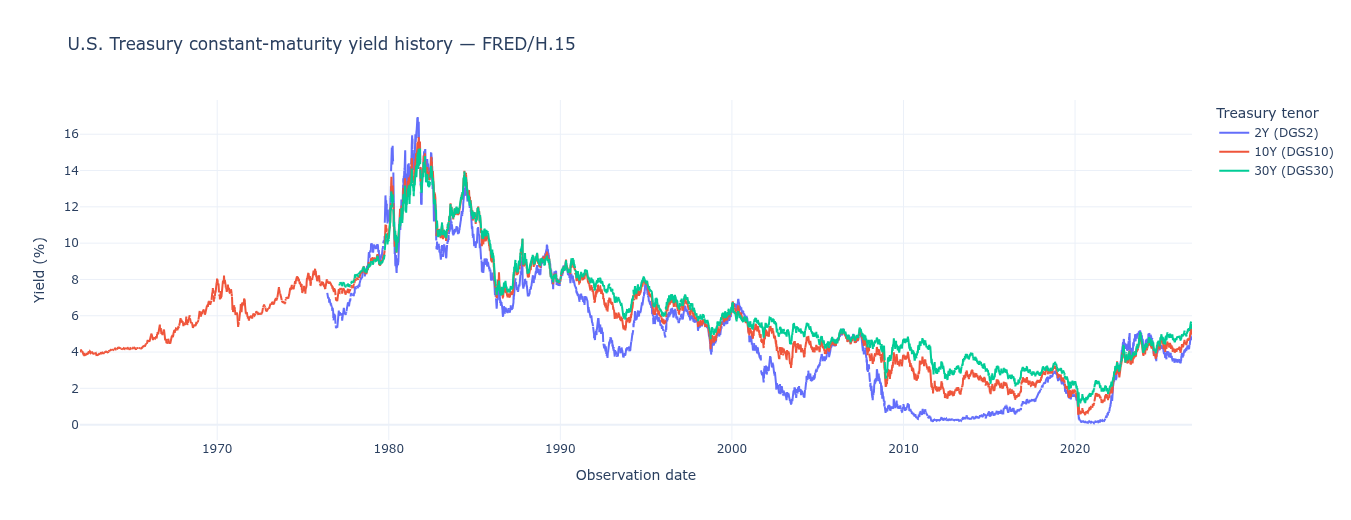

In [6]:
history_figure = show_yield_history(
    observations, *date_range.get_dates()
)

### Treasury yield and curve movements

Calculate yield and spread changes between selected dates, classify curve movements, and display the results

In [7]:
result = analyze_curve(
    observations, *date_range.get_dates(),
    yield_change_tolerance_bp=5,
    slope_tolerance_bp=5,
)
show_curve_results(result)

,1962-01-02,2026-10-26,Change,Curve configuration,Movement / regime
Treasury measure,,,,,
2Y yield,N/A,4.68%,N/A,—,N/A
10Y yield,4.06%,5.00%,+94 bp,—,Yield rose
30Y yield,N/A,5.31%,N/A,—,N/A
10Y−2Y spread,N/A,+32 bp,N/A,N/A → Upward-sloping,N/A
30Y−10Y spread,N/A,+31 bp,N/A,N/A → Upward-sloping,N/A


Greatest upward yield movement among available tenors: 10Y (+94 bp). This comparison is partial because some endpoint observations are unavailable. 10Y−2Y spread: N/A. 30Y−10Y spread: N/A. These are net endpoint movements, not the full path or a forecast.

## B. Expected short rates and term premiums

*Load KW model estimates*

In [3]:
from bondview.plotting.treasury_curve import show_kw_decomposition

kw_observations = fred.load(
    series_ids=["THREEFY2", "THREEFYTP2", "THREEFY10", "THREEFYTP10"]
)

### 2Y and 10Y yield decomposition

In [4]:
date_range = DateRangePicker(kw_observations)

In [7]:
date_range

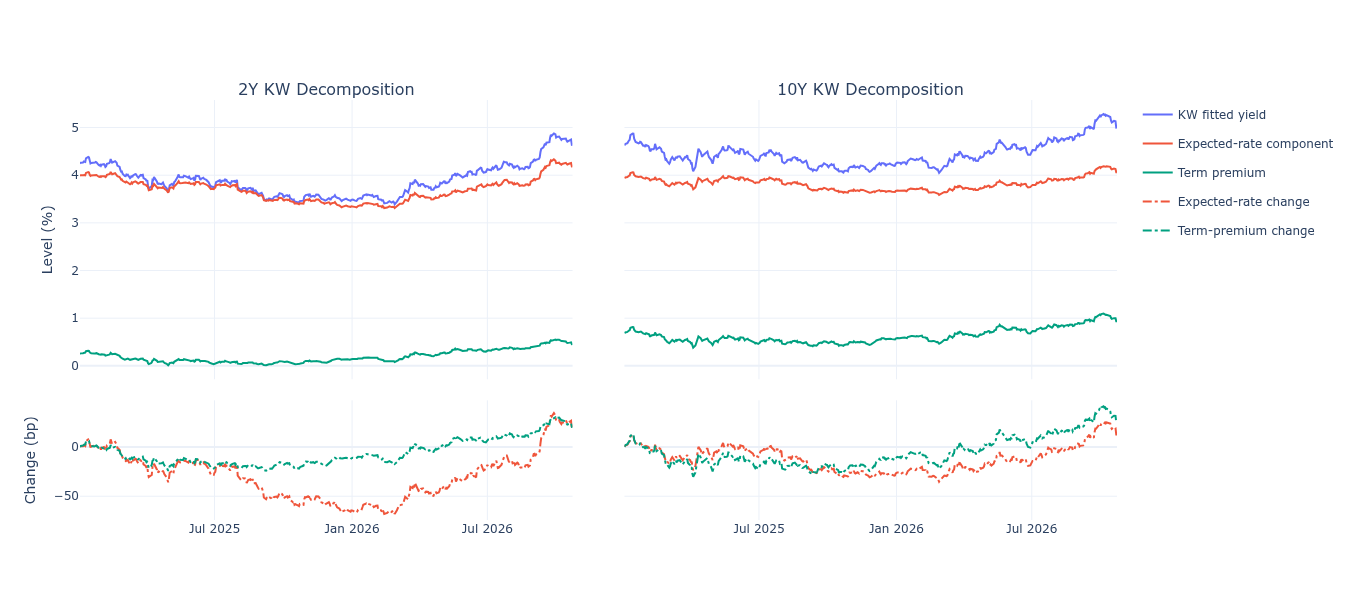

In [8]:
show_kw_decomposition(kw_observations, *date_range.get_dates(), width=1300, height=600)

## C. Conditional joint yield movements

### Investor-conditioned historical scenarios

### KW expectations-conditioned historical scenarios

### Joint scenario-set summary